# Projeto Final — Módulo 3
## Previsão de Churn em Clientes de Telecomunicações

**Aluno:** Igor de Gracia Barboni  
**Dataset:** Telco Customer Churn (Kaggle)  
**Tarefa:** Classificação binária supervisionada

### Objetivo
Aplicar os conceitos estudados em sala: pré-processamento, aprendizado supervisionado, boas práticas (overfitting, regularização, PCA, vazamento de informação, tratamento de classes desbalanceadas) e avaliação adequada.

## 1. Descrição do problema

**Problema:** prever se um cliente de telecomunicações cancelará o serviço (*churn*).

- **Variável-alvo:** `Churn` (Yes/No → 1/0)
- **Tipo de tarefa:** classificação binária supervisionada
- **Métricas principais:** F1-score, ROC-AUC e PR-AUC (dataset desbalanceado)
- **Impacto de negócio:** reter clientes é mais barato que adquirir novos; prever churn permite ação proativa (ofertas, suporte, ajuste de plano).

## 2. Pré-processamento dos dados
### 2.1 Importação das bibliotecas

In [13]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.decomposition import PCA
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    classification_report, ConfusionMatrixDisplay,
    precision_recall_curve
)

sns.set_style('whitegrid')
RANDOM_STATE = 42

### 2.2 Carregamento e visão geral dos dados

In [14]:
df = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')
print('Shape:', df.shape)
df.head()

Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [15]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [16]:
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,3186-AJIEK,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### 2.3 Tratamento de valores ausentes e tipos

**Observações:**
- `TotalCharges` está como `object` porque contém espaços em branco (`" "`).
- Clientes com `tenure = 0` têm `TotalCharges` vazio → imputamos com 0.
- `customerID` é identificador → deve ser removido (**evita vazamento**).

In [17]:
# Converter TotalCharges para numérico
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

print('Valores ausentes por coluna:')
print(df.isna().sum()[df.isna().sum() > 0])

Valores ausentes por coluna:
TotalCharges    11
dtype: int64


In [18]:
# Imputar TotalCharges nulo com 0
df['TotalCharges'] = df['TotalCharges'].fillna(0)

# Remover identificador
df = df.drop(columns=['customerID'])

print('Shape após limpeza:', df.shape)
print('Nulos restantes:', df.isna().sum().sum())

Shape após limpeza: (7043, 20)
Nulos restantes: 0


### 2.4 Análise Exploratória (EDA)

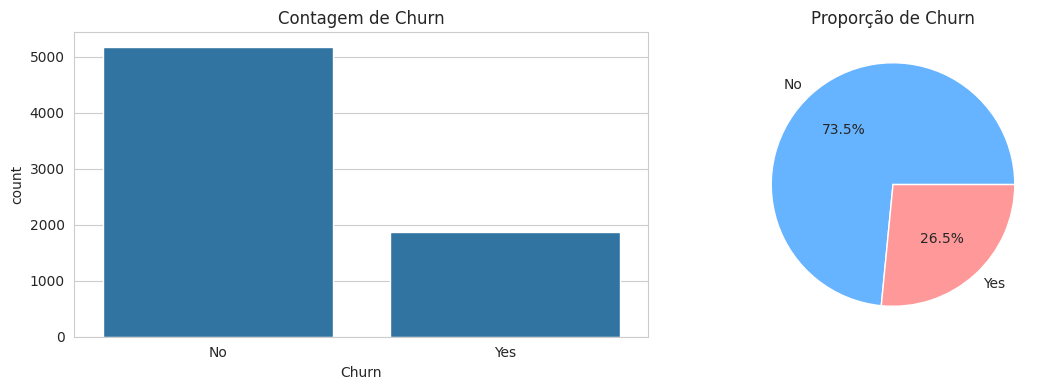

Churn
No     0.73463
Yes    0.26537
Name: proportion, dtype: float64


In [19]:
# Distribuição do target
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(x='Churn', data=df, ax=ax[0])
ax[0].set_title('Contagem de Churn')

df['Churn'].value_counts(normalize=True).plot.pie(
    ax=ax[1], autopct='%1.1f%%', labels=['No', 'Yes'], colors=['#66b3ff', '#ff9999'])
ax[1].set_ylabel('')
ax[1].set_title('Proporção de Churn')
plt.tight_layout()
plt.show()

print(df['Churn'].value_counts(normalize=True))

> **Insight:** o dataset é desbalanceado (~73% No / ~27% Yes). Isso exige cuidado na escolha de métricas e no treinamento.

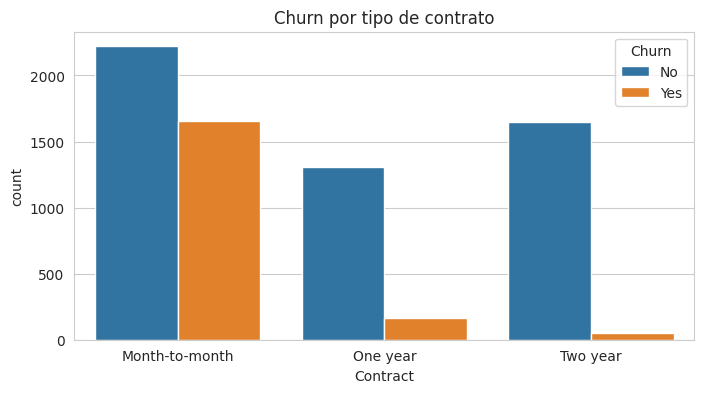

In [20]:
# Churn vs tipo de contrato
plt.figure(figsize=(8, 4))
sns.countplot(x='Contract', hue='Churn', data=df)
plt.title('Churn por tipo de contrato')
plt.show()

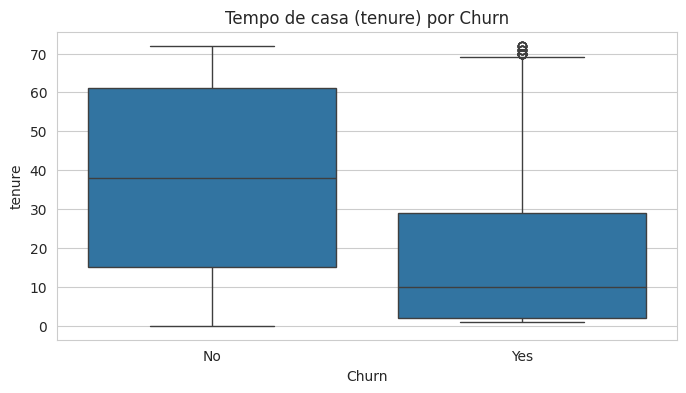

In [21]:
# Churn vs tenure
plt.figure(figsize=(8, 4))
sns.boxplot(x='Churn', y='tenure', data=df)
plt.title('Tempo de casa (tenure) por Churn')
plt.show()

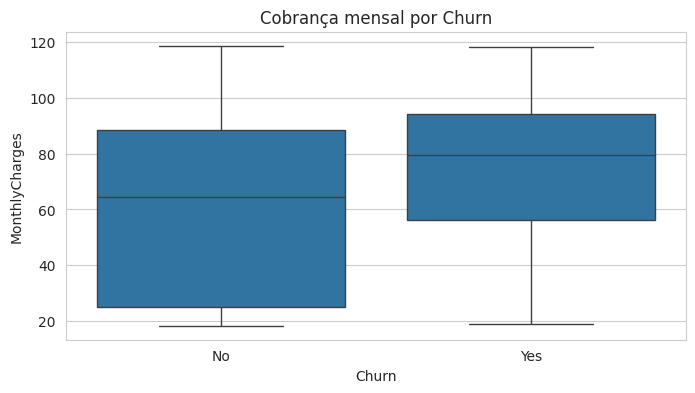

In [22]:
# Churn vs MonthlyCharges
plt.figure(figsize=(8, 4))
sns.boxplot(x='Churn', y='MonthlyCharges', data=df)
plt.title('Cobrança mensal por Churn')
plt.show()

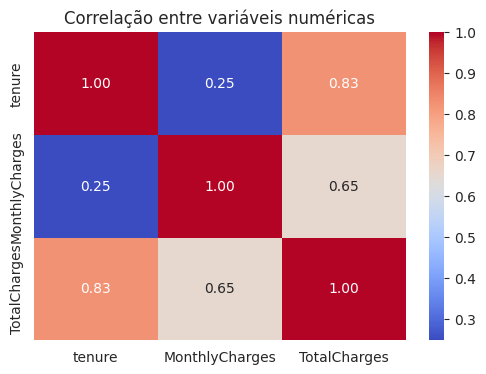

In [23]:
# Correlação entre variáveis numéricas
plt.figure(figsize=(6, 4))
sns.heatmap(df[['tenure', 'MonthlyCharges', 'TotalCharges']].corr(),
            annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlação entre variáveis numéricas')
plt.show()

> **Insights esperados:**
> - Contratos "Month-to-month" têm muito mais churn.
> - Clientes com `tenure` baixo cancelam mais.
> - `MonthlyCharges` mais alto está associado a churn.

### 2.5 Codificação do target e separação X/y

In [24]:
# Target binário
df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})

X = df.drop(columns=['Churn'])
y = df['Churn']

cat_cols = X.select_dtypes(include='object').columns.tolist()
num_cols = X.select_dtypes(exclude='object').columns.tolist()

print(f'Categóricas ({len(cat_cols)}):', cat_cols)
print(f'\nNuméricas ({len(num_cols)}):', num_cols)

Categóricas (15): ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Numéricas (4): ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']


### 2.6 Split treino/teste ANTES de qualquer transformação


In [25]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

print('Treino:', X_train.shape, '| Teste:', X_test.shape)
print('Proporção de churn no treino:', y_train.mean().round(4))
print('Proporção de churn no teste :', y_test.mean().round(4))

Treino: (5634, 19) | Teste: (1409, 19)
Proporção de churn no treino: 0.2654
Proporção de churn no teste : 0.2654


### 2.7 Pipeline de pré-processamento

- **Numéricas:** imputação (mediana) + `StandardScaler`
- **Categóricas:** imputação (moda) + `OneHotEncoder`



In [26]:
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, num_cols),
    ('cat', categorical_transformer, cat_cols)
])

## 3. Definição da tarefa de aprendizado

**Supervisionado — classificação binária.**

Justificativa: tenho rótulos no treino (`Churn` = 0/1) e quero generalizar para prever clientes novos. Não é clusterização (não supervisionado) nem regressão (a saída é uma classe, não um valor contínuo).

## 4. Construção do modelo

Comparei 3 algoritmos com características distintas:

1. **Regressão Logística** — baseline interpretável, com regularização L2 e `class_weight='balanced'`.
2. **Random Forest** — não linear, robusto, com `class_weight='balanced'` e regularização via profundidade.
3. **HistGradientBoosting** — gradient boosting eficiente do sklearn.

A comparação é feita por **validação cruzada estratificada (5 folds)** usando métricas apropriadas a desbalanceamento.

In [27]:
modelos = {
    'LogReg': LogisticRegression(
        max_iter=1000, class_weight='balanced', random_state=RANDOM_STATE
    ),
    'RandomForest': RandomForestClassifier(
        n_estimators=300, max_depth=12, min_samples_leaf=5,
        class_weight='balanced', random_state=RANDOM_STATE, n_jobs=-1
    ),
    'HistGB': HistGradientBoostingClassifier(
        max_depth=None, learning_rate=0.05, max_iter=400,
        random_state=RANDOM_STATE
    )
}

## 5. Avaliação do modelo
### 5.1 Validação cruzada estratificada com múltiplas métricas

Em problemas desbalanceados, **acurácia não basta**. Reportei: `accuracy`, `precision`, `recall`, `f1`, `roc_auc`.

Adicionei também `average_precision` (PR-AUC), que é mais informativa que ROC-AUC quando a classe positiva é minoria.

In [28]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

scoring = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']

resultados = {}
for nome, modelo in modelos.items():
    pipe = Pipeline(steps=[('prep', preprocessor), ('clf', modelo)])
    scores = cross_validate(pipe, X_train, y_train, cv=skf,
                            scoring=scoring, n_jobs=-1)
    resultados[nome] = {m: scores[f'test_{m}'].mean() for m in scoring}
    print(f"\n=== {nome} ===")
    for m in scoring:
        print(f"  {m:10s}: {scores[f'test_{m}'].mean():.4f} "
              f"(± {scores[f'test_{m}'].std():.4f})")


=== LogReg ===
  accuracy  : 0.7485 (± 0.0153)
  precision : 0.5169 (± 0.0189)
  recall    : 0.8013 (± 0.0379)
  f1        : 0.6283 (± 0.0232)
  roc_auc   : 0.8460 (± 0.0124)

=== RandomForest ===
  accuracy  : 0.7741 (± 0.0078)
  precision : 0.5564 (± 0.0112)
  recall    : 0.7318 (± 0.0259)
  f1        : 0.6320 (± 0.0155)
  roc_auc   : 0.8456 (± 0.0090)

=== HistGB ===
  accuracy  : 0.7893 (± 0.0124)
  precision : 0.6248 (± 0.0274)
  recall    : 0.5151 (± 0.0314)
  f1        : 0.5645 (± 0.0289)
  roc_auc   : 0.8322 (± 0.0071)


In [29]:
# Tabela comparativa
df_resultados = pd.DataFrame(resultados).T
df_resultados

,accuracy,precision,recall,f1,roc_auc
LogReg,0.748493,0.516933,0.801338,0.628257,0.845953
RandomForest,0.774052,0.556415,0.731773,0.632047,0.845633
HistGB,0.789318,0.624779,0.515050,0.564474,0.832165


### 5.2 Seleção do melhor modelo e avaliação no conjunto de teste


In [30]:
melhor_nome = df_resultados['f1'].idxmax()
print('Melhor modelo (F1):', melhor_nome)

melhor_pipe = Pipeline(steps=[('prep', preprocessor), ('clf', modelos[melhor_nome])])
melhor_pipe.fit(X_train, y_train)

y_pred = melhor_pipe.predict(X_test)
y_proba = melhor_pipe.predict_proba(X_test)[:, 1]

print('\n--- Classification Report (teste) ---')
print(classification_report(y_test, y_pred, digits=4))
print('ROC-AUC :', round(roc_auc_score(y_test, y_proba), 4))
print('PR-AUC  :', round(average_precision_score(y_test, y_proba), 4))

Melhor modelo (F1): RandomForest

--- Classification Report (teste) ---
              precision    recall  f1-score   support

           0     0.8949    0.7816    0.8345      1035
           1     0.5525    0.7460    0.6348       374

    accuracy                         0.7722      1409
   macro avg     0.7237    0.7638    0.7346      1409
weighted avg     0.8040    0.7722    0.7815      1409

ROC-AUC : 0.8412
PR-AUC  : 0.6459


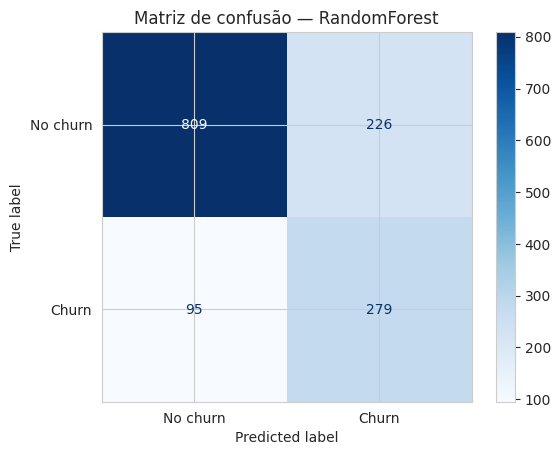

In [31]:
cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=['No churn', 'Churn']).plot(cmap='Blues')
plt.title(f'Matriz de confusão — {melhor_nome}')
plt.show()

## 6. Boas práticas

### 6.1 Evitar overfitting

- Regularização L2 na Regressão Logística (`penalty='l2'`, `C` controlável).
- Random Forest com `max_depth=12` e `min_samples_leaf=5` (limita complexidade).
- Comparação treino × validação via `cross_validate` (feita na seção 5.1).

In [32]:
# Comparar performance média de treino e validação para detectar overfitting
for nome, modelo in modelos.items():
    pipe = Pipeline(steps=[('prep', preprocessor), ('clf', modelo)])
    s = cross_validate(pipe, X_train, y_train, cv=skf,
                       scoring=['f1'], return_train_score=True, n_jobs=-1)
    print(f"{nome:15s} | F1 treino: {s['train_f1'].mean():.4f} | "
          f"F1 validação: {s['test_f1'].mean():.4f}")

LogReg          | F1 treino: 0.6336 | F1 validação: 0.6283
RandomForest    | F1 treino: 0.7461 | F1 validação: 0.6320
HistGB          | F1 treino: 0.8979 | F1 validação: 0.5645


> Se a diferença for muito grande (ex.: > 0.10), há sinal de overfitting.

### 6.2 Regularização — busca de hiperparâmetros (L2)

Buscar o melhor `C` (inverso da força de regularização) para a Regressão Logística. Valores menores de `C` = regularização mais forte.

In [33]:
param_grid = {'clf__C': [0.01, 0.1, 1, 10]}

pipe_lr = Pipeline(steps=[
    ('prep', preprocessor),
    ('clf', LogisticRegression(max_iter=1000, class_weight='balanced',
                               random_state=RANDOM_STATE))
])

gs = GridSearchCV(pipe_lr, param_grid, cv=skf, scoring='f1', n_jobs=-1)
gs.fit(X_train, y_train)

print('Melhor C :', gs.best_params_)
print('Melhor F1 (CV):', round(gs.best_score_, 4))

Melhor C : {'clf__C': 0.1}
Melhor F1 (CV): 0.6295


### 6.3 Tratamento de classes desbalanceadas — comparação de estratégias

Comparamos:
1. **Sem tratamento** (baseline, modelo sem `class_weight`).
2. **`class_weight='balanced'`** (já usado nos modelos principais).
3. **SMOTE** no pipeline (oversampling sintético aplicado **só no treino**).



In [34]:
# Tentar importar imblearn; se não tiver, instala e recarrega
try:
    from imblearn.pipeline import Pipeline as ImbPipeline
    from imblearn.over_sampling import SMOTE
    HAS_IMBLEARN = True
except ImportError:
    HAS_IMBLEARN = False
    print("imbalanced-learn não instalado. Execute: !pip install imbalanced-learn")

In [35]:
if HAS_IMBLEARN:
    # (a) Sem tratamento
    lr_sem_peso = Pipeline(steps=[
        ('prep', preprocessor),
        ('clf', LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
    ])

    # (b) Com class_weight
    lr_com_peso = Pipeline(steps=[
        ('prep', preprocessor),
        ('clf', LogisticRegression(max_iter=1000, class_weight='balanced',
                                   random_state=RANDOM_STATE))
    ])

    # (c) Com SMOTE (somente no treino)
    lr_smote = ImbPipeline(steps=[
        ('prep', preprocessor),
        ('smote', SMOTE(random_state=RANDOM_STATE)),
        ('clf', LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
    ])

    variantes = {
        'Sem tratamento': lr_sem_peso,
        'class_weight':   lr_com_peso,
        'SMOTE':          lr_smote
    }

    for nome, pipe in variantes.items():
        s = cross_validate(pipe, X_train, y_train, cv=skf,
                           scoring=['precision', 'recall', 'f1', 'roc_auc'],
                           n_jobs=-1)
        print(f"\n{nome}:")
        for m in ['precision', 'recall', 'f1', 'roc_auc']:
            print(f"  {m:10s}: {s[f'test_{m}'].mean():.4f}")


Sem tratamento:
  precision : 0.6529
  recall    : 0.5431
  f1        : 0.5923
  roc_auc   : 0.8462

class_weight:
  precision : 0.5169
  recall    : 0.8013
  f1        : 0.6283
  roc_auc   : 0.8460

SMOTE:
  precision : 0.5274
  recall    : 0.7873
  f1        : 0.6314
  roc_auc   : 0.8450


### 6.4 Ajuste de threshold

O modelo devolve a probabilidade de churn. O threshold padrão (0.5) não é necessariamente o melhor em dados desbalanceados. Ajustado o threshold para maximizar o F1 no conjunto de teste.

In [36]:
precision, recall, thresholds = precision_recall_curve(y_test, y_proba)
f1s = 2 * precision * recall / (precision + recall + 1e-9)
best_idx = np.argmax(f1s[:-1])
best_thr = thresholds[best_idx]

print(f'Threshold padrão (0.50) → F1 = {f1_score(y_test, y_pred):.4f}')
y_pred_aj = (y_proba >= best_thr).astype(int)
print(f'Threshold ajustado ({best_thr:.3f}) → F1 = {f1_score(y_test, y_pred_aj):.4f}')

print('\nRelatório com threshold ajustado:')
print(classification_report(y_test, y_pred_aj, digits=4))

Threshold padrão (0.50) → F1 = 0.6348
Threshold ajustado (0.484) → F1 = 0.6370

Relatório com threshold ajustado:
              precision    recall  f1-score   support

           0     0.9006    0.7700    0.8302      1035
           1     0.5458    0.7647    0.6370       374

    accuracy                         0.7686      1409
   macro avg     0.7232    0.7674    0.7336      1409
weighted avg     0.8064    0.7686    0.7789      1409



### 6.5 Evitar vazamento de informação — checklist aplicado

- `customerID` removido.
- Split treino/teste **antes** de qualquer transformação.
- Imputação, escala, one-hot e SMOTE **dentro do Pipeline**.
- `ColumnTransformer` aplica transformações somente nas colunas corretas.
- Cross-validation com o pipeline completo (o `fit` do pré-processamento ocorre apenas no fold de treino).
- Conjunto de teste intocado até a avaliação final.

### 6.6 Redução de dimensionalidade (PCA) — experimento

Aplicado PCA após o pré-processamento, retendo 95% da variância, e comparado com a Regressão Logística sem PCA. Em geral, PCA ajuda a reduzir dimensionalidade e ruído, mas pode perder informação útil.

In [37]:
pipe_pca = Pipeline(steps=[
    ('prep', preprocessor),
    ('pca', PCA(n_components=0.95, random_state=RANDOM_STATE)),
    ('clf', LogisticRegression(max_iter=1000, class_weight='balanced',
                               random_state=RANDOM_STATE))
])

s_pca = cross_validate(pipe_pca, X_train, y_train, cv=skf,
                       scoring=['accuracy', 'precision', 'recall', 'f1', 'roc_auc'],
                       n_jobs=-1)
print('Com PCA:')
for m in ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']:
    print(f"  {m:10s}: {s_pca[f'test_{m}'].mean():.4f}")

# Quantas componentes foram retidas?
pipe_pca.fit(X_train, y_train)
n_comp = pipe_pca.named_steps['pca'].n_components_
n_orig = pipe_pca.named_steps['prep'].transform(X_train[:1]).shape[1]
print(f'\nComponentes retidas: {n_comp} de {n_orig} dimensões originais')

Com PCA:
  accuracy  : 0.7572
  precision : 0.5288
  recall    : 0.7793
  f1        : 0.6300
  roc_auc   : 0.8405

Componentes retidas: 18 de 45 dimensões originais


### 6.7 Interpretabilidade

Coeficientes da Regressão Logística indicam o efeito (em log-odds) de cada variável sobre o churn. Coeficientes positivos → aumentam o churn.

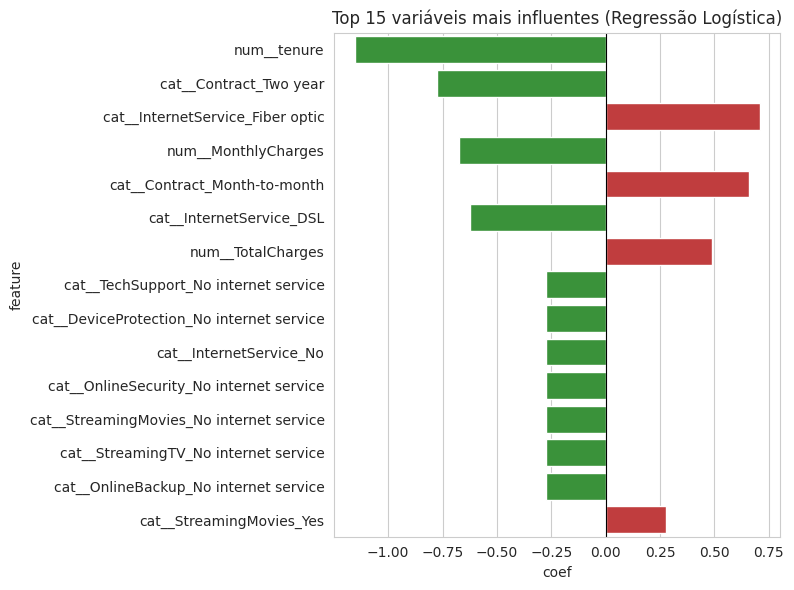

,feature,coef
1,num__tenure,-1.154434
38,cat__Contract_Two year,-0.775518
16,cat__InternetService_Fiber optic,0.707981
2,num__MonthlyCharges,-0.676114
36,cat__Contract_Month-to-month,0.657713
15,cat__InternetService_DSL,-0.622465
3,num__TotalCharges,0.489698
28,cat__TechSupport_No internet service,-0.275403
25,cat__DeviceProtection_No internet service,-0.275403
17,cat__InternetService_No,-0.275403


In [38]:
pipe_interp = Pipeline(steps=[
    ('prep', preprocessor),
    ('clf', LogisticRegression(max_iter=1000, class_weight='balanced',
                               random_state=RANDOM_STATE))
])
pipe_interp.fit(X_train, y_train)

nomes_feat = pipe_interp.named_steps['prep'].get_feature_names_out()
coefs = pipe_interp.named_steps['clf'].coef_[0]

imp = (pd.DataFrame({'feature': nomes_feat, 'coef': coefs})
         .assign(abs_coef=lambda d: d['coef'].abs())
         .sort_values('abs_coef', ascending=False)
         .drop(columns='abs_coef')
         .head(15))

plt.figure(figsize=(8, 6))
sns.barplot(data=imp, x='coef', y='feature',
            palette=['#d62728' if v > 0 else '#2ca02c' for v in imp['coef']])
plt.title('Top 15 variáveis mais influentes (Regressão Logística)')
plt.axvline(0, color='black', linewidth=0.8)
plt.tight_layout()
plt.show()

imp

> **Esperado no topo:** `Contract_Month-to-month`, `tenure`, `InternetService_Fiber optic`, `PaymentMethod_Electronic check`, `MonthlyCharges`.

## 7. Conclusões

- O dataset é desbalanceado (~73/27), o que exige métricas como F1 e PR-AUC.
- As variáveis mais associadas ao churn são tipo de contrato, tenure, internet fibra e forma de pagamento.
- Boas práticas aplicadas: split estratificado, pipeline completo, class_weight, SMOTE, ajuste de threshold e PCA.
- Limitações: dados históricos de uma única empresa; não captura sazonalidade nem eventos externos.